# Aligning weather with satellite passes

`gaia align` treats two kinds of time differently. Weather grids (ERA5, HRRR, PRISM,
Stage IV) cover every hour or day, and are combined in time with each other. Satellite
scenes (Sentinel-1, Sentinel-2) are snapshots at their passes: they are put on the same
grid, but keep their acquisition times.

This notebook stages Sentinel-1 and ERA5 around the 2023-09-14 Peters Dome ice-rock
avalanche, Alaska, and aligns them two ways:

- **A. Keep both times.** ERA5 stays hourly; weather between passes is computed when
  needed.
- **B. Weather on the passes.** `--time-like rasters/sentinel1-rtc` sums ERA5 from one
  pass to the next.

ERA5 needs a free Earthmover account: set `ARRAYLAKE_TOKEN` before starting Jupyter
(see [](../docs/datasets.md)).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  registers .rio
import xarray as xr

out = Path("/tmp/peters-dome-align")  # every store below is written here
out.mkdir(parents=True, exist_ok=True)
event = pd.Timestamp("2023-09-14T02:06:49")  # ComCat origin
SOURCE_Z = 2760  # m, the source's approximate elevation
LAPSE_RATE = 6.5e-3  # degC per m, a standard atmosphere's

## Stage

Every Sentinel-1 pass on the source's track in the 36 days either side of the event,
and hourly ERA5 precipitation, snowfall and 2 m temperature. ERA5's snowfall `sf` is
the part of the total `tp` that fell as snow (both in mm of water), so rain is
`tp - sf`.

ERA5 starts one 12-day repeat earlier: the first pass has no earlier one in the store,
so in B its interval reaches back one repeat, and it would be NaN if ERA5 started with
the passes (it would reach beyond ERA5's time span).

In [2]:
stage = out / "stage.yaml"
stage.write_text("""
name: peters-dome-align
time: 2023-09-14T02:06:49Z
aoi: {latitude: 63.1455, longitude: -151.1904, radius_km: 15}
datasets:
  sentinel1-rtc:
    window: {pre: {before: 36d}, post: {after: 36d}}
    match: relative_orbit
  era5:
    variables: [tp, sf, t2m] # precipitation, snow fall, 2m temperature
    window: {before: 48d, after: 36d}  # one 12-day repeat before the first pass
""")
staged = out / "staged" / "peters-dome-align.zarr"

In [3]:
!gaia stage --config {stage} -o {out}/staged --overwrite 2>&1 | grep -E "loading|Error|Done"

18:07:22 [   1.3s] runner: sentinel1-rtc: loading (2023-08-09T02:06:49/2023-09-14T02:06:49, 2023-09-14T02:06:49/2023-10-20T02:06:49, read as 2023-08-09T02:06:49/2023-10-20T02:06:49)
18:08:00 [  39.2s] runner: era5: loading (2023-07-28T02:06:49/2023-10-20T02:06:49, read as 2023-07-27T02:06:49/2023-10-21T02:06:49)
18:08:05 [  44.2s] runner: Done


## A. Keep both times

By default the time step is the coarsest weather dataset's, here ERA5's hour, and the
Sentinel-1 passes keep theirs. A 300 m grid keeps the store small; on Sentinel-1's own
10 m grid, hourly ERA5 would be hundreds of GB, which `gaia align` refuses (over 10 GB).

In [4]:
!gaia align -i {staged} -o {out}/hourly --crs EPSG:32605 --res 300 --overwrite 2>&1 | grep -E "keeping|target|Error"

18:08:07 [   1.6s] align: rasters/sentinel1-rtc: keeping its acquisition times (scenes)
18:08:07 [   1.6s] align: time target rasters/era5 (2064 step(s))
18:08:08 [   1.9s] align: grid target EPSG:32605 at 300.0 (190 x 132 cells)


In [5]:
hourly = xr.open_datatree(out / "hourly" / "hourly.zarr", engine="zarr")
s1 = hourly["rasters/sentinel1-rtc"].to_dataset()
era5 = hourly["rasters/era5"].to_dataset()
print(hourly.attrs["gaia_align"])
for name, ds in [("Sentinel-1", s1), ("ERA5", era5)]:
    print(f"{name}: {ds.sizes['time']} times on {ds.sizes['y']} x {ds.sizes['x']} cells")
print("passes:", ", ".join(f"{t:%b %d %H:%M}" for t in pd.to_datetime(s1.time.values)))

grid=EPSG:32605 at 300.0; time=rasters/era5; method=per variable; scenes=kept
Sentinel-1: 6 times on 190 x 132 cells
ERA5: 2064 times on 190 x 132 cells
passes: Aug 16 16:29, Aug 28 16:29, Sep 09 16:29, Sep 21 16:29, Oct 03 16:29, Oct 15 16:29


### The grids

ERA5 comes on a 0.25° grid: six cells, each about 13 x 28 km here, cover the 15 km
AOI. Sentinel-1 comes on a 10 m UTM grid. `gaia align` puts both on the 300 m UTM
target grid, which covers every staged raster, so it reaches as far as the ERA5 cells
do. ERA5's precipitation is regridded conservatively, which onto a finer grid means
each 300 m cell takes the value of the ERA5 cell it lies in: the blocks in the middle
panel.

The numbers on the left are each ERA5 cell's `orography` minus the ~2,760 m source
elevation. `orography` is the height of ERA5's own terrain, smoothed to roughly the
cell's mean: it is the level ERA5's surface values are valid at, not the ground under
the source. Here the cells sit 0.6–1.5 km below the summit, so ERA5's 2 m
temperature is several degrees warmer than at the source, and its rain/snow split is
too rainy. Regridding to 300 m doesn't change that: each 300 m cell inherits its ERA5
cell's height. Below, a lapse rate estimates the temperature at the source.

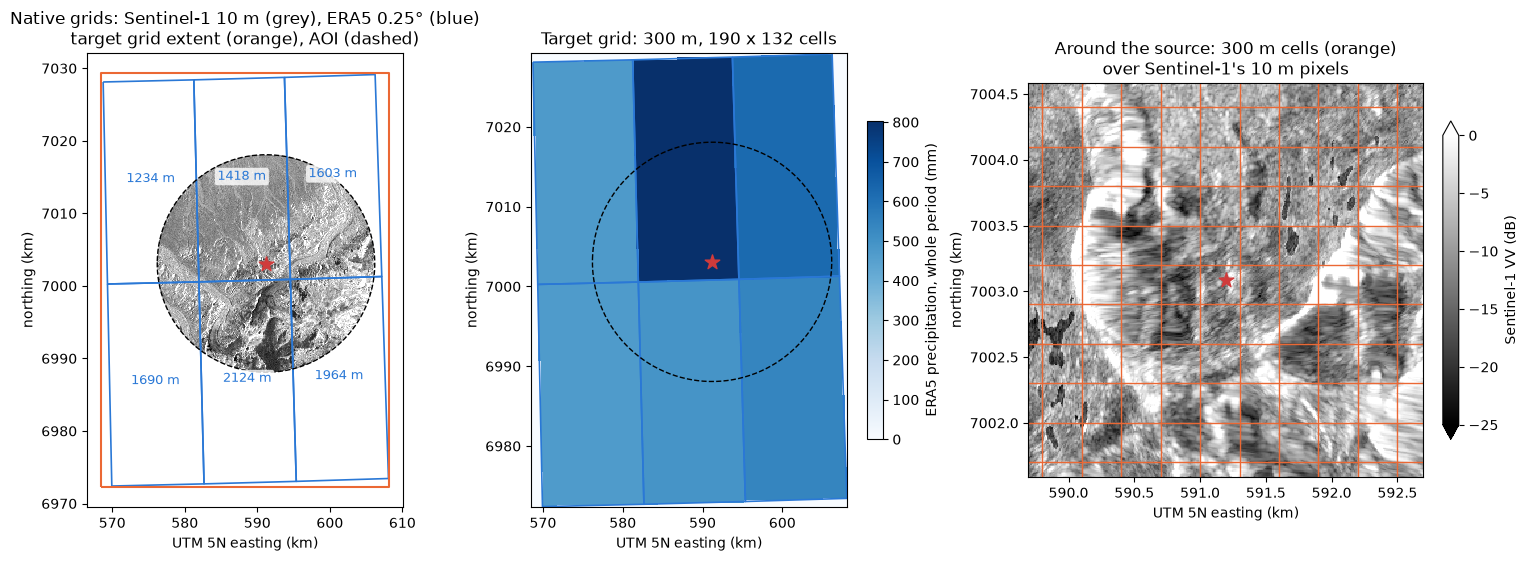

In [6]:
import geopandas as gpd
from shapely.geometry import Point, box

from gaia_cli.aoi import load_aoi

native = xr.open_datatree(staged, engine="zarr")
s1_native = native["rasters/sentinel1-rtc"].to_dataset()
era5_native = native["rasters/era5"].to_dataset()
utm = s1.rio.crs
aoi = load_aoi({"latitude": 63.1455, "longitude": -151.1904, "radius_km": 15}).to_crs(utm)
source = gpd.GeoSeries([Point(-151.1904, 63.1455)], crs="EPSG:4326").to_crs(utm)
# Each ERA5 cell, a 0.25° box around its centre, drawn in UTM
ys, xs = np.meshgrid(era5_native.y.values, era5_native.x.values, indexing="ij")
era5_cells = gpd.GeoDataFrame(
    {"orography": era5_native.orography.values.ravel()},
    geometry=[box(x - 0.125, y - 0.125, x + 0.125, y + 0.125) for x, y in zip(xs.ravel(), ys.ravel())],
    crs="EPSG:4326",
).to_crs(utm)
target = gpd.GeoSeries([box(*era5.rio.bounds())], crs=utm)


def db(da):
    return 10 * np.log10(da)


def outline(ax):
    era5_cells.boundary.plot(ax=ax, color="#2a78d6", lw=1.2)
    aoi.boundary.plot(ax=ax, color="k", lw=1, ls="--")
    source.plot(ax=ax, color="#d03b3b", marker="*", markersize=120, zorder=3)


fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), layout="constrained")
ax = axes[0]
db(s1_native.vv.isel(time=0)).coarsen(x=5, y=5, boundary="trim").mean().plot.imshow(
    ax=ax, cmap="gray", vmin=-25, vmax=0, add_colorbar=False
)
outline(ax)
target.boundary.plot(ax=ax, color="#eb6834", lw=1.5)
for cell in era5_cells.itertuples():
    c = cell.geometry.centroid
    ax.annotate(f"{cell.orography - SOURCE_Z:+,.0f} m", (c.x, c.y), ha="center", color="#2a78d6", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, lw=0))
ax.set_title("Native grids: Sentinel-1 10 m (grey), ERA5 0.25° (blue)\ntarget grid extent (orange), AOI (dashed)\nlabels: ERA5 terrain height minus the source's")

ax = axes[1]
era5.tp.sum("time").plot.imshow(ax=ax, cmap="Blues", cbar_kwargs={"label": "ERA5 precipitation, whole period (mm)", "shrink": 0.7})
outline(ax)
ax.set_title(f"Target grid: 300 m, {era5.sizes['y']} x {era5.sizes['x']} cells")

ax = axes[2]
x0, y0 = source.x.iloc[0], source.y.iloc[0]
half = 1500  # m
zoom = s1_native.vv.isel(time=0).sel(x=slice(x0 - half, x0 + half), y=slice(y0 + half, y0 - half))
db(zoom).plot.imshow(ax=ax, cmap="gray", vmin=-25, vmax=0, cbar_kwargs={"label": "Sentinel-1 VV (dB)", "shrink": 0.7})
edges_x = era5.x.values - 150  # the target cells' edges
edges_y = era5.y.values + 150
ax.vlines(edges_x, y0 - half, y0 + half, color="#eb6834", lw=1)
ax.hlines(edges_y, x0 - half, x0 + half, color="#eb6834", lw=1)
source.plot(ax=ax, color="#d03b3b", marker="*", markersize=120, zorder=3)
ax.set(xlim=(x0 - half, x0 + half), ylim=(y0 - half, y0 + half))
ax.set_title("Around the source: 300 m cells (orange)\nover Sentinel-1's 10 m pixels")
km = plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}")
for ax in axes:
    ax.set(aspect="equal", xlabel="UTM 5N easting (km)", ylabel="northing (km)")
    ax.xaxis.set_major_formatter(km)
    ax.yaxis.set_major_formatter(km)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.1f}"))
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.1f}"))

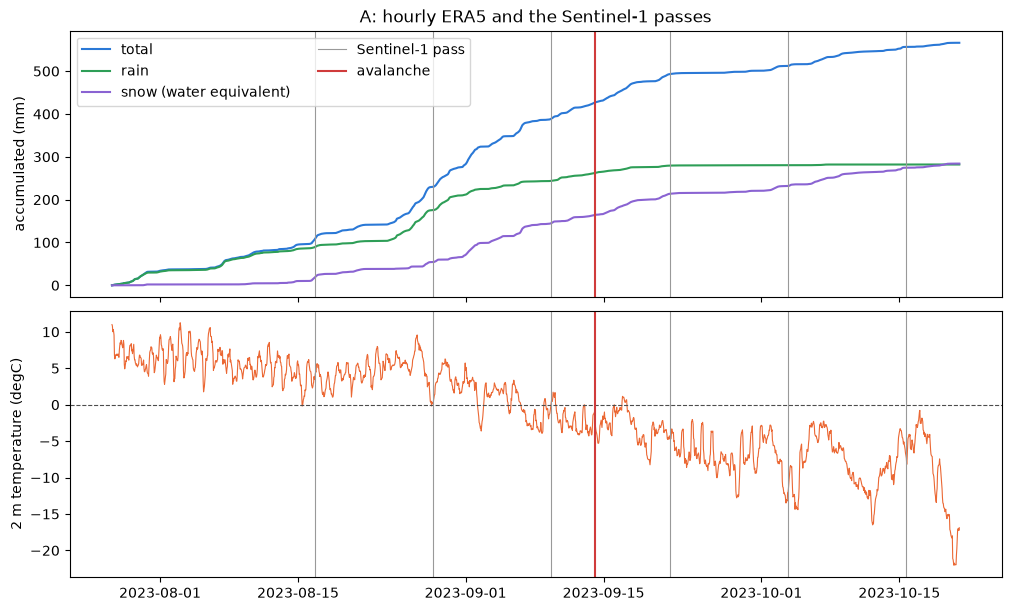

In [7]:
grid = ["y", "x"]
tp, sf, t2m = (era5[v].mean(grid) for v in ("tp", "sf", "t2m"))  # over the grid
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
top.plot(tp.time, tp.cumsum("time"), color="#2a78d6", label="total")
top.plot(tp.time, (tp - sf).cumsum("time"), color="#2e9e57", label="rain")
top.plot(tp.time, sf.cumsum("time"), color="#8a63d2", label="snow (water equivalent)")
top.set(ylabel="accumulated (mm)", title="A: hourly ERA5 and the Sentinel-1 passes")
# ERA5's t2m is valid at its terrain height; a standard lapse rate moves it up to the source
dz = SOURCE_Z - float(era5.orography.mean(grid))
bottom.plot(t2m.time, t2m, color="#eb6834", lw=0.8, label=f"ERA5, at its terrain ({SOURCE_Z - dz:,.0f} m)")
bottom.plot(t2m.time, t2m - LAPSE_RATE * dz, color="#eb6834", lw=0.8, ls="--", label=f"at the source ({SOURCE_Z:,} m, lapse rate)")
bottom.axhline(0, color="0.3", lw=0.8, ls="--")
bottom.set(ylabel="2 m temperature (degC)")
for ax in (top, bottom):
    for i, t in enumerate(s1.time.values):
        ax.axvline(t, color="0.6", lw=0.8, label="Sentinel-1 pass" if i == 0 else None)
    ax.axvline(event, color="#d03b3b", lw=1.5, label="avalanche")
top.legend(loc="upper left", ncols=2)
bottom.legend(handles=bottom.get_lines()[:2], loc="lower left");

Weather between passes comes from the hourly values. Each ERA5 value is stamped at the
end of its hour: the value at 17:00 fell between 16:00 and 17:00. `align.overlap` gives
the fraction of each hour that lies between two passes: 1 for the hours wholly between
them, and a share for the hour a pass falls inside (29/60 of 16:00–17:00 before a pass
at 16:29, 31/60 after it). Summing the hours with those weights loses no precipitation.

In [8]:
from gaia_cli import align

passes = s1.time.values
weights = align.overlap(era5.time_bounds, passes[:-1], passes[1:])  # (step, time)
between = xr.dot(weights, tp, dim="time")
between.round(1)

<xarray.DataArray (step: 5)> Size: 40B
array([122.7, 159. , 104.2,  19.1,  44.4])
Coordinates:
    spatial_ref  int64 8B 0
Dimensions without coordinates: step

### Weather at each pass

A's hourly store also gives the weather at the acquisition itself. ERA5 values are
hour-ending, so the precipitation for a pass at 16:29 is the value stamped 17:00
(`method="bfill"`); 2 m temperature is instantaneous, so it is interpolated between the
hours either side, and is ERA5's at its terrain height, about a kilometre below the
source (see the dashed line above for an estimate there). The snow share is `sf / tp`, the part of that hour's precipitation
that ERA5 has falling as snow; it is left blank for hours with under 0.1 mm, a cutoff
chosen here to skip trace amounts.

In [9]:
hour = {v: era5[v].sel(time=s1.time, method="bfill").mean(grid).values for v in ("tp", "sf")}
at_pass = pd.DataFrame(
    {
        "pass": pd.to_datetime(s1.time.values).floor("min"),
        "precipitation that hour (mm)": hour["tp"].round(2),
        "of which snow (mm)": hour["sf"].round(2),
        "snow share (%)": np.where(hour["tp"] >= 0.1, 100 * hour["sf"] / hour["tp"], np.nan).round(),
        "2 m temperature (degC)": era5.t2m.interp(time=s1.time).mean(grid).values.round(1),
    }
)
at_pass

,pass,precipitation that hour (mm),of which snow (mm),snow share (%),2 m temperature (degC)
0,2023-08-16 16:29:00,1.26,0.87,69.0,3.6
1,2023-08-28 16:29:00,0.13,0.02,15.0,0.3
2,2023-09-09 16:29:00,0.53,0.39,73.0,0.3
3,2023-09-21 16:29:00,0.18,0.15,85.0,-4.4
4,2023-10-03 16:29:00,0.05,0.05,NaN,-12.0
5,2023-10-15 16:29:00,0.00,0.00,NaN,-7.1


## B. Weather on the passes

With a scene dataset as `--time-like`, each step runs from one pass to the next (the
first from one typical repeat before it), and ERA5 is combined into it by its
`cell_methods`: precipitation and snowfall summed, temperature averaged. Missing hours
within ERA5's time span are skipped; a step reaching beyond it is NaN.

In [10]:
!gaia align -i {staged} -o {out}/passes --crs EPSG:32605 --res 300 --time-like rasters/sentinel1-rtc --overwrite 2>&1 | grep -E "keeping|target|Error"

18:08:15 [   1.1s] align: rasters/sentinel1-rtc: keeping its acquisition times (scenes)
18:08:15 [   1.1s] align: time target rasters/sentinel1-rtc (6 step(s))
18:08:15 [   1.1s] align: grid target EPSG:32605 at 300.0 (190 x 132 cells)


In [11]:
passes = xr.open_datatree(out / "passes" / "passes.zarr", engine="zarr")
weather = passes["rasters/era5"].to_dataset()
table = pd.DataFrame(
    {
        "from": pd.to_datetime(weather.time_bounds.values[:, 0]).floor("min"),
        "to (pass)": pd.to_datetime(weather.time_bounds.values[:, 1]).floor("min"),
        "precipitation (mm)": weather.tp.mean(["y", "x"]).values.round(1),
        "of which snow (mm)": weather.sf.mean(["y", "x"]).values.round(1),
        "mean 2 m temperature (degC)": weather.t2m.mean(["y", "x"]).values.round(1),
    }
)
print(weather.tp.attrs["aggregated_from"])
table

steps of 60 minutes, weighted by their overlap with each target step


,from,to (pass),precipitation (mm),of which snow (mm),mean 2 m temperature (degC)
0,2023-08-04 16:29:00,2023-08-16 16:29:00,69.400002,16.100000,5.3
1,2023-08-16 16:29:00,2023-08-28 16:29:00,122.699997,36.200001,4.7
2,2023-08-28 16:29:00,2023-09-09 16:29:00,159.000000,90.699997,1.2
3,2023-09-09 16:29:00,2023-09-21 16:29:00,104.199997,68.599998,-2.7
4,2023-09-21 16:29:00,2023-10-03 16:29:00,19.100000,18.100000,-6.9
5,2023-10-03 16:29:00,2023-10-15 16:29:00,44.400002,42.799999,-8.1


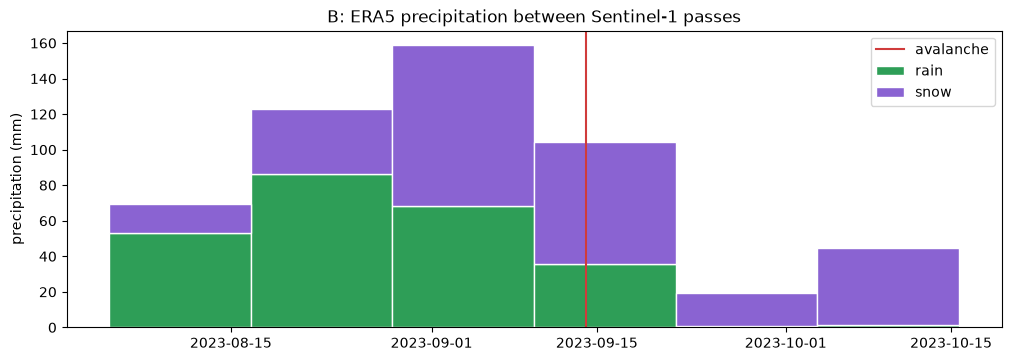

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
lo, hi = pd.to_datetime(weather.time_bounds.values[:, 0]), pd.to_datetime(weather.time_bounds.values[:, 1])
snow = table["of which snow (mm)"]
rain = table["precipitation (mm)"] - snow
ax.bar(lo, rain, width=hi - lo, align="edge", color="#2e9e57", edgecolor="white", label="rain")
ax.bar(lo, snow, width=hi - lo, bottom=rain, align="edge", color="#8a63d2", edgecolor="white", label="snow")
ax.axvline(event, color="#d03b3b", lw=1.5, label="avalanche")
ax.set(ylabel="precipitation (mm)", title="B: ERA5 precipitation between Sentinel-1 passes")
ax.legend(loc="upper right");

The two approaches agree: `gaia align` weights the hours the same way, so B's totals
are A's hourly values summed between passes.

In [13]:
np.testing.assert_allclose(between, weather.tp.mean(["y", "x"]).values[1:], atol=0.001)
print("A and B agree")

A and B agree


## Which to use

- **A** keeps everything: hourly weather for any window you choose later (the day
  before a pass, the hours around the event). The store grows with the hours, so use a
  coarse grid.
- **B** gives one value per pass interval, ready to compare with the backscatter
  change, and a small store even on the scenes' own grid.
- For the weather at the acquisition itself, select from A's hours at the pass times.
- `--align-scenes` also combines the scenes in time, onto the same steps as the
  weather. Passes in a step are then averaged, which is rarely what you want for
  imagery.